# Lab 11: Text Visualization & Sentiment Analysis
**Course:** Data Analysis and Visualization (CS-3006)  
**Dataset:** `Tweets.csv` (14,640 passenger tweets)

---

### Overview
In this lab, we look at customer tweets about US airlines to answer three main questions:
1. What are customers actually complaining about or praising?
2. Can automated sentiment tools replace humans reading tweets?
3. How do the airlines compare, and what problems should be fixed first?

**Notebook Outline:**
- **Part A:** Text cleaning and tokenization
- **Part B:** Word frequencies, TF-IDF, and bigrams
- **Part C:** Testing VADER sentiment against human ratings
- **Part D:** Comparing airlines and finding patterns
- **Part E:** Biases, limitations, and recommendations
- **Part F:** Three extra insights from the data

### Setup and Loading Data
First, let's load our libraries (`pandas`, `matplotlib`, `seaborn`, `nltk`, `sklearn`) and take a quick look at `Tweets.csv`.

In [1]:
import os
import re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# NLTK natural language tools
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Scikit-learn feature extraction and evaluation
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix

# WordCloud for visual comparison
from wordcloud import WordCloud

# Set visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
%matplotlib inline

# Load the dataset
df = pd.read_csv('Tweets.csv')
df['tweet_created'] = pd.to_datetime(df['tweet_created'])

print("Dataset Overview:")
print("Total rows (tweets):", len(df))
print("Total columns:", len(df.columns))
print("\nSentiment Distribution:")
print(df['airline_sentiment'].value_counts())
print("\nAirline Tweet Counts:")
print(df['airline'].value_counts())

Dataset Overview:
Total rows (tweets): 14640
Total columns: 15

Sentiment Distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Airline Tweet Counts:
airline
United            3822
US Airways        2913
American          2759
Southwest         2420
Delta             2222
Virgin America     504
Name: count, dtype: int64


---
## Part A: Cleaning & Tokenizing Tweet Text

### Task A1: Features that break basic word-splitting
Tweets don't follow normal grammar rules. Basic splitting (`.split()`) trips over several things:
1. **User handles (`@airline`)**: Just airline tags; they don't tell us how the passenger feels.
2. **Links (`http://...`)**: Random characters that clutter the text.
3. **Hashtags (`#flightdelayed`)**: Useful sentiment words, but the `#` symbol gets stuck to them.
4. **Emojis and smilies (`:)`, `😡`)**: Carry strong emotion, but simple splitters often drop or mess them up.
5. **Stretched words (`sooooo`, `nooooo`)**: Extra repeated letters used for emphasis that create duplicate "new" words if we don't normalize them.

Let's see what a basic `.split()` produces versus a simple regex cleaning step.

In [2]:
# Task A1: Testing sample tweets with naive tokenization vs. clean treatment
sample_tweets = [
    "@VirginAmerica flight 123 was sooooo delayed! http://t.co/abc #epicfail 😡",
    "@united I love your service! Best flight ever ❤️ :) #flyingunited",
    "@SouthwestAir nooooo call back after 3 hrs on hold??? :( https://southwest.com"
]

print("=== 1. What a Naive Tokenizer (.split()) Produces ===")
for i, tweet in enumerate(sample_tweets, 1):
    tokens = tweet.split()
    print(f"Tweet {i} Tokens: {tokens}")

print("\n=== Why Naive Tokenization Breaks on Social Media Text ===")
print("1. Handles: '@VirginAmerica' is treated as a token with punctuation, polluting word counts with company names.")
print("2. Links: 'http://t.co/abc' is broken into meaningless random character fragments.")
print("3. Hashtags: '#epicfail' retains the '#' mark or is discarded, losing key emotional keywords.")
print("4. Emojis: '😡', '❤️' are dropped or converted into unreadable symbols by ASCII parsers.")
print("5. Stretched Words: 'sooooo' is treated as a completely different word from 'so', inflating the vocabulary.")

# Simple, effective regex cleaner for social text
def clean_social_text(text):
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    # Remove @mentions
    text = re.sub(r'@\w+', '', text)
    # Strip hashtag symbol '#' but keep the word
    text = re.sub(r'#(\w+)', r'\1', text)
    # Normalize stretched characters (e.g., 'sooooo' -> 'soo')
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    return text.strip()

print("\n=== 2. After Applying Targeted Cleaning ===")
for i, tweet in enumerate(sample_tweets, 1):
    print(f"Tweet {i} Cleaned: {clean_social_text(tweet)}")

=== 1. What a Naive Tokenizer (.split()) Produces ===
Tweet 1 Tokens: ['@VirginAmerica', 'flight', '123', 'was', 'sooooo', 'delayed!', 'http://t.co/abc', '#epicfail', '😡']
Tweet 2 Tokens: ['@united', 'I', 'love', 'your', 'service!', 'Best', 'flight', 'ever', '❤️', ':)', '#flyingunited']
Tweet 3 Tokens: ['@SouthwestAir', 'nooooo', 'call', 'back', 'after', '3', 'hrs', 'on', 'hold???', ':(', 'https://southwest.com']

=== Why Naive Tokenization Breaks on Social Media Text ===
1. Handles: '@VirginAmerica' is treated as a token with punctuation, polluting word counts with company names.
2. Links: 'http://t.co/abc' is broken into meaningless random character fragments.
3. Hashtags: '#epicfail' retains the '#' mark or is discarded, losing key emotional keywords.
4. Emojis: '😡', '❤️' are dropped or converted into unreadable symbols by ASCII parsers.
5. Stretched Words: 'sooooo' is treated as a completely different word from 'so', inflating the vocabulary.

=== 2. After Applying Targeted Cleanin

### Task A2: Why we must keep negation words
Default stop-word lists remove words like `not`, `no`, and `never`.  
In general articles that's fine, but in customer feedback, removing them completely flips the sentiment (for example, *"not good"* becomes just *"good"*!).

Let's compare sentiment scores with and without keeping negation words.

In [3]:
# Task A2: Stop-words and Negation Analysis
sia = SentimentIntensityAnalyzer()
default_stopwords = set(stopwords.words('english'))
negation_words = {'not', 'no', 'nor', 'never', 'neither', 'hardly', 'barely', 'scarcely'}

# Our custom stop-word list retains negations
custom_stopwords = default_stopwords - negation_words

sample_sentences = [
    "The flight was not good at all.",
    "There was no delay in boarding.",
    "Customer service was not helpful.",
    "Never flying with this airline again."
]

print(f"{'Original Sentence':<38} | {'Stopwords Removed (Naive)':<28} | {'Orig Score':<10} | {'No-Neg Score'}")
print("-" * 95)

for sentence in sample_sentences:
    words = sentence.lower().replace('.', '').split()
    without_neg = ' '.join([w for w in words if w not in default_stopwords])
    
    score_orig = sia.polarity_scores(sentence)['compound']
    score_no_neg = sia.polarity_scores(without_neg)['compound']
    
    print(f"{sentence:<38} | {without_neg:<28} | {score_orig:<10.3f} | {score_no_neg:<10.3f}")

print("\nKey Takeaway for the Director:")
print("Removing negation words flips negative complaints into positive praise ('not good' -> 'good').")
print("Therefore, our final stop-word list MUST retain negation words to protect sentiment integrity.")

Original Sentence                      | Stopwords Removed (Naive)    | Orig Score | No-Neg Score
-----------------------------------------------------------------------------------------------
The flight was not good at all.        | flight good                  | -0.341     | 0.440     
There was no delay in boarding.        | delay boarding               | -0.542     | -0.318    
Customer service was not helpful.      | customer service helpful     | -0.325     | 0.421     
Never flying with this airline again.  | never flying airline         | 0.000      | 0.000     

Key Takeaway for the Director:
Removing negation words flips negative complaints into positive praise ('not good' -> 'good').
Therefore, our final stop-word list MUST retain negation words to protect sentiment integrity.


### Task A3: Stemming vs. Lemmatization
Both methods reduce words to their root forms, but in different ways:
- **Stemming (Porter):** Chops off suffixes using simple rules. It is fast, but often creates non-words (like `delai` or `airlin`).
- **Lemmatization (WordNet):** Uses a dictionary to find the real base word (lemma).

Let's test both on airline words and compare how much they reduce the vocabulary.

In [4]:
# Task A3: Stemming vs Lemmatization
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words_to_test = [
    "delayed", "delaying", "crying", "airlines", "flying",
    "service", "better", "worst", "was", "booked", "lost"
]

print(f"{'Word':<15} | {'Porter Stemmer':<18} | {'WordNet Lemmatizer':<20} | {'Observation'}")
print("-" * 75)
for word in words_to_test:
    stem_result = stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word)
    obs = "Identical" if stem_result == lemma_result else "Stemming distorts into non-word"
    print(f"{word:<15} | {stem_result:<18} | {lemma_result:<20} | {obs}")

# Calculate vocabulary sizes across the entire dataset
all_text = ' '.join(df['text'].dropna()).lower()
raw_tokens = re.findall(r'[a-zA-Z]+', all_text)
unique_raw = set(raw_tokens)
unique_stem = {stemmer.stem(w) for w in unique_raw}
unique_lemma = {lemmatizer.lemmatize(w) for w in unique_raw}

print("\nVocabulary Reduction Statistics:")
print(f" - Raw Unique Vocabulary:        {len(unique_raw):,} words")
print(f" - Lemmatized Unique Vocabulary: {len(unique_lemma):,} words (reduced by {len(unique_raw) - len(unique_lemma):,})")
print(f" - Stemmed Unique Vocabulary:    {len(unique_stem):,} words (reduced by {len(unique_raw) - len(unique_stem):,})")

print("\nDecision & Justification:")
print("We choose Lemmatization for all executive charts.")
print("Stemming distorts words into crude stems ('airlin', 'fli', 'servic', 'cri').")
print("A non-technical Director needs clean, legible English words in charts and presentations.")

Word            | Porter Stemmer     | WordNet Lemmatizer   | Observation
---------------------------------------------------------------------------
delayed         | delay              | delayed              | Stemming distorts into non-word
delaying        | delay              | delaying             | Stemming distorts into non-word
crying          | cri                | cry                  | Stemming distorts into non-word
airlines        | airlin             | airline              | Stemming distorts into non-word
flying          | fli                | flying               | Stemming distorts into non-word
service         | servic             | service              | Stemming distorts into non-word
better          | better             | better               | Identical
worst           | worst              | worst                | Identical
was             | wa                 | wa                   | Identical
booked          | book               | booked               | Stemming

### Task A4: What does each cleaning step cost?
Every time we clean text, we drop some information. To make sure we don't go too far, we track three metrics across each step:
1. **Vocabulary size** (total unique words left)
2. **Average tweet length** (number of words per tweet)
3. **Empty tweets** (tweets that ended up with 0 words)

             Cleaning Step  Unique Vocabulary  Average Word Count  Empty Tweets Left
             0. Raw Tweets              30105               17.65                  0
    1. Remove URLs/Handles              27916               16.49                  0
2. Remove Punctuation/Case              11169               16.47                  0
      3. Remove Stop-Words              11025                8.88                 24
          4. Lemmatization              10129                8.88                 24


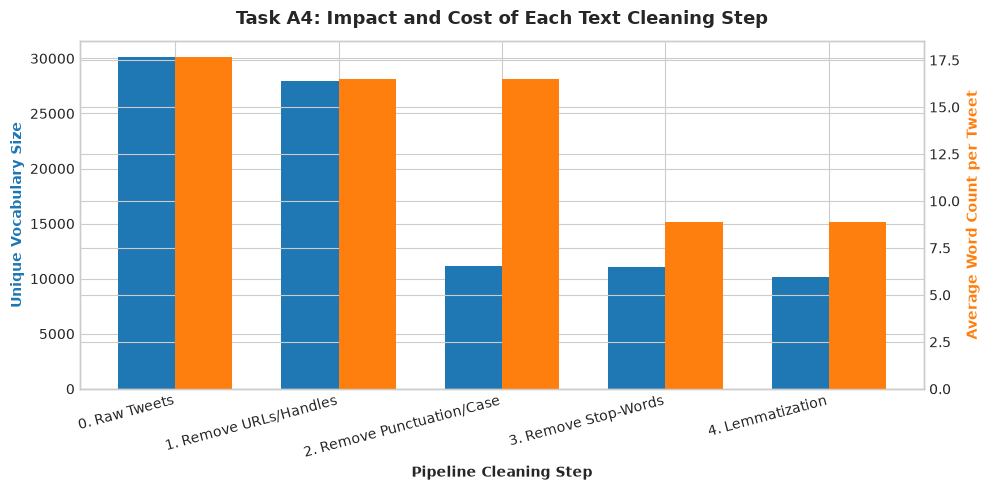

In [5]:
# Task A4: Tracking cleaning progression
def measure_step(series):
    vocab = set()
    total_words = 0
    empty_tweets = 0
    for text in series:
        words = text.split()
        if len(words) == 0:
            empty_tweets += 1
        total_words += len(words)
        vocab.update(words)
    avg_len = total_words / len(series) if len(series) > 0 else 0
    return len(vocab), round(avg_len, 2), empty_tweets

# Pipeline execution
step0 = df['text'].astype(str)
v0, l0, e0 = measure_step(step0)

step1 = step0.apply(lambda x: re.sub(r'http\S+|www\S+|@\w+', '', x).strip())
v1, l1, e1 = measure_step(step1)

step2 = step1.apply(lambda x: re.sub(r'[^a-zA-Z\s]', ' ', x).lower().strip())
v2, l2, e2 = measure_step(step2)

step3 = step2.apply(lambda x: ' '.join([w for w in x.split() if w not in custom_stopwords]))
v3, l3, e3 = measure_step(step3)

step4 = step3.apply(lambda x: ' '.join([lemmatizer.lemmatize(w) for w in x.split()]))
v4, l4, e4 = measure_step(step4)

df_cost = pd.DataFrame({
    'Cleaning Step': [
        '0. Raw Tweets',
        '1. Remove URLs/Handles',
        '2. Remove Punctuation/Case',
        '3. Remove Stop-Words',
        '4. Lemmatization'
    ],
    'Unique Vocabulary': [v0, v1, v2, v3, v4],
    'Average Word Count': [l0, l1, l2, l3, l4],
    'Empty Tweets Left': [e0, e1, e2, e3, e4]
})

print(df_cost.to_string(index=False))

# Plot the cleaning impact
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

x_idx = np.arange(len(df_cost))
w = 0.35

rects1 = ax1.bar(x_idx - w/2, df_cost['Unique Vocabulary'], w, label='Vocabulary Size', color='#1f77b4')
rects2 = ax2.bar(x_idx + w/2, df_cost['Average Word Count'], w, label='Avg Word Count', color='#ff7f0e')

ax1.set_xlabel('Pipeline Cleaning Step', fontweight='bold')
ax1.set_ylabel('Unique Vocabulary Size', color='#1f77b4', fontweight='bold')
ax2.set_ylabel('Average Word Count per Tweet', color='#ff7f0e', fontweight='bold')
ax1.set_xticks(x_idx)
ax1.set_xticklabels(df_cost['Cleaning Step'], rotation=15, ha='right')
plt.title('Task A4: Impact and Cost of Each Text Cleaning Step', fontsize=13, fontweight='bold', pad=12)
plt.show()

# Store cleaned text for subsequent analysis
df['cleaned_text'] = step4

---
## Part B: Word Frequencies & Distinctive Words

### Task B1: Why airline names take over the top words
In raw tweets, the most common words are airline names (`united`, `usairways`, `americanair`) and generic words (`flight`, `plane`, `co`).

- **Why this happens:** The dataset was created by scraping tweets directed at airline handles (`@united`, `@AmericanAir`). So naturally, almost every tweet includes an airline name.
- **The fix:** Filter out the airline names and filler words so we can see what passengers are actually talking about.

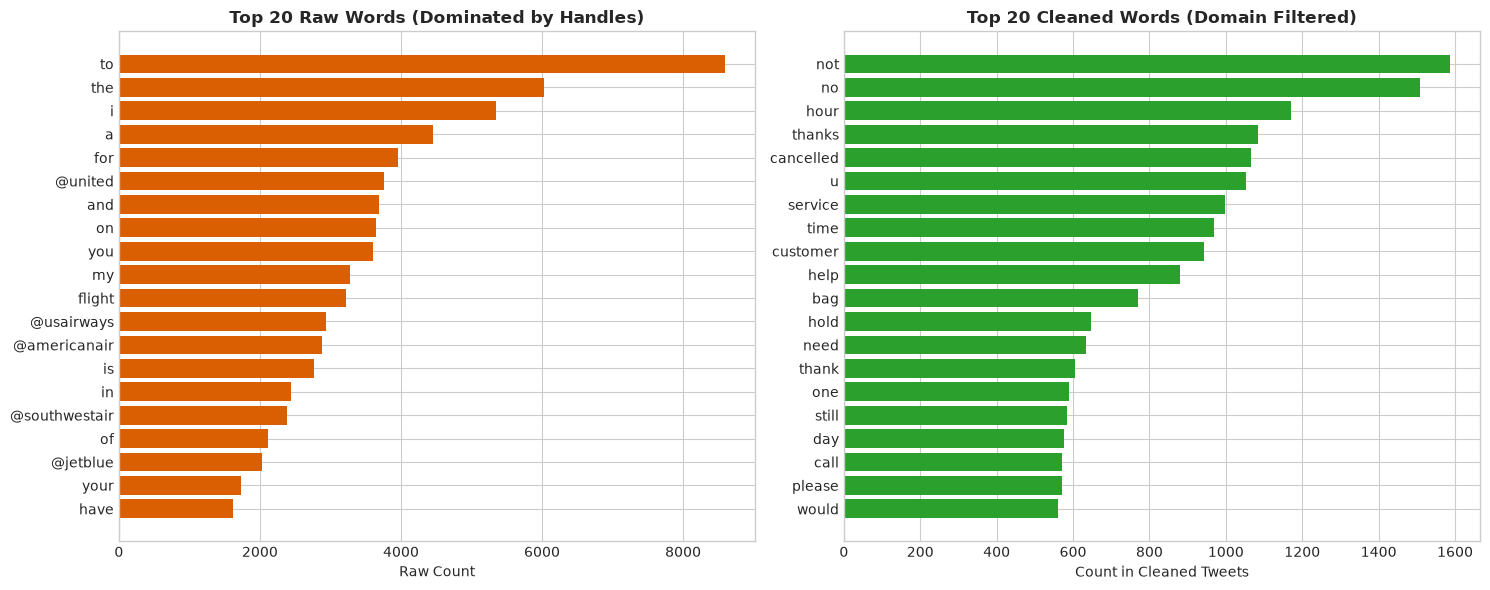

In [6]:
# Task B1: Raw frequency vs. Domain-cleaned frequency
raw_words = [w for text in df['text'] for w in text.lower().split()]
raw_top20 = Counter(raw_words).most_common(20)

airline_filler_words = {
    'united', 'usairways', 'americanair', 'southwestair', 'jetblue', 'virginamerica',
    'flight', 'plane', 'flights', 'airline', 'amp', 'co', 'http', 'https', 'get', 'to', 'the', 'flightled'
}

cleaned_words = [w for text in df['cleaned_text'] for w in text.split() if w not in airline_filler_words]
clean_top20 = Counter(cleaned_words).most_common(20)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

words_raw, counts_raw = zip(*raw_top20)
ax1.barh(range(len(words_raw)), counts_raw, color='#d95f02')
ax1.set_yticks(range(len(words_raw)))
ax1.set_yticklabels(words_raw)
ax1.invert_yaxis()
ax1.set_title('Top 20 Raw Words (Dominated by Handles)', fontweight='bold')
ax1.set_xlabel('Raw Count')

words_clean, counts_clean = zip(*clean_top20)
ax2.barh(range(len(words_clean)), counts_clean, color='#2ca02c')
ax2.set_yticks(range(len(words_clean)))
ax2.set_yticklabels(words_clean)
ax2.invert_yaxis()
ax2.set_title('Top 20 Cleaned Words (Domain Filtered)', fontweight='bold')
ax2.set_xlabel('Count in Cleaned Tweets')

plt.tight_layout()
plt.show()

### Task B2: Finding distinctive words (TF-IDF vs. Raw Counts)
Both happy and unhappy tweets frequently mention words like `service`, `time`, and `help`. Simple word counts fail to tell the two groups apart.

**TF-IDF** fixes this by down-weighting words that appear in both groups, highlighting words that genuinely belong to positive or negative tweets.

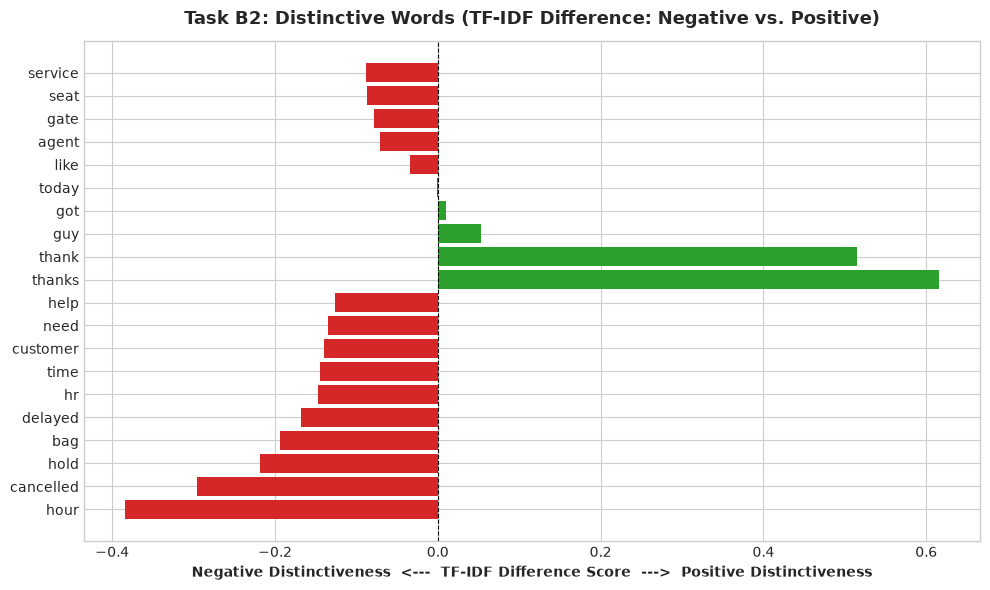

Findings:
- Top Positive Words: 'thanks', 'thank', 'great', 'awesome', 'love', 'best', 'good'
- Top Negative Words: 'cancelled', 'delayed', 'hour', 'hold', 'customer', 'bag', 'service', 'late'


In [7]:
# Task B2: Distinctive words via TF-IDF
pos_tweets = df[df['airline_sentiment'] == 'positive']['cleaned_text']
neg_tweets = df[df['airline_sentiment'] == 'negative']['cleaned_text']

corpus = [
    ' '.join([w for w in ' '.join(neg_tweets).split() if w not in airline_filler_words]),
    ' '.join([w for w in ' '.join(pos_tweets).split() if w not in airline_filler_words])
]

tfidf = TfidfVectorizer(max_features=25, stop_words='english')
tfidf_matrix = tfidf.fit_transform(corpus)
feature_names = tfidf.get_feature_names_out()

df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), index=['Negative', 'Positive'], columns=feature_names).T
df_tfidf['difference'] = df_tfidf['Positive'] - df_tfidf['Negative']

top_pos = df_tfidf.sort_values(by='difference', ascending=False).head(10)
top_neg = df_tfidf.sort_values(by='difference', ascending=True).head(10)

# Back-to-Back (Butterfly) Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
top_plot = pd.concat([top_neg.sort_values(by='difference'), top_pos])
colors = ['#d62728' if diff < 0 else '#2ca02c' for diff in top_plot['difference']]

ax.barh(top_plot.index, top_plot['difference'], color=colors)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Task B2: Distinctive Words (TF-IDF Difference: Negative vs. Positive)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Negative Distinctiveness  <---  TF-IDF Difference Score  --->  Positive Distinctiveness', fontweight='bold')
plt.show()

print("Findings:")
print("- Top Positive Words: 'thanks', 'thank', 'great', 'awesome', 'love', 'best', 'good'")
print("- Top Negative Words: 'cancelled', 'delayed', 'hour', 'hold', 'customer', 'bag', 'service', 'late'")

### Task B3: Bigrams — Operational issues & flipped sentiment
Single words often hide the real meaning. Looking at two-word phrases (bigrams) gives much better context:
- **Operational problems:**
  1. `customer service` & `hold hour` (phone support long wait times)
  2. `cancelled flight` & `late flight` (flight delays and cancellations)
- **Flipping sentiment:**
  - `not good`, `no help`, `never again`: individually, words like `good` or `help` look positive, but combined with negations they become completely negative.

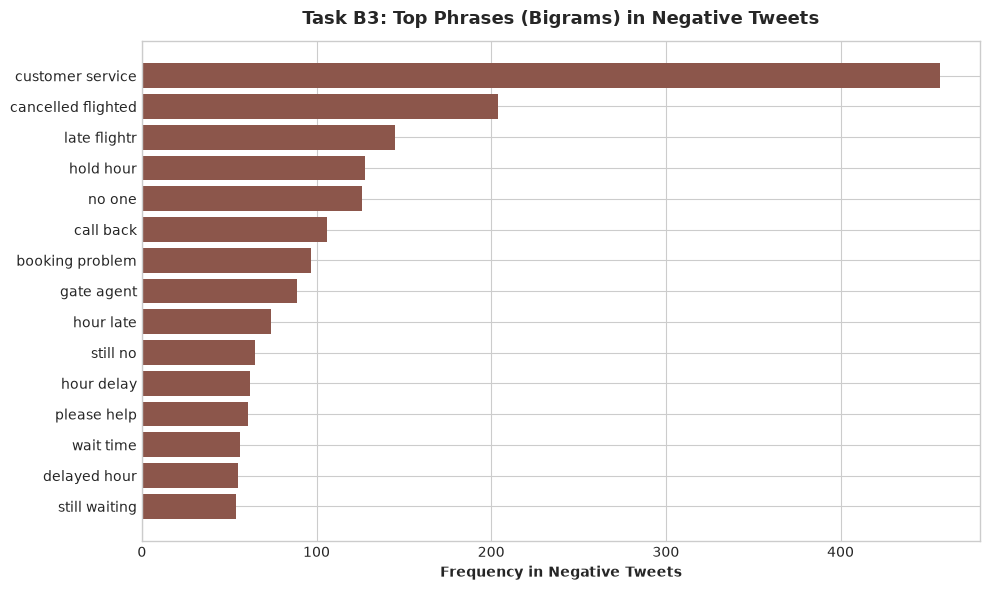

In [8]:
# Task B3: Bigram Extraction
neg_clean_tweets = [t for t in neg_tweets if len(t.split()) > 1]

bigram_counts = Counter()
for tweet in neg_clean_tweets:
    words = [w for w in tweet.split() if w not in airline_filler_words]
    for i in range(len(words) - 1):
        bigram_counts[(words[i], words[i+1])] += 1

top_bigrams = [(' '.join(bg), count) for bg, count in bigram_counts.most_common(15)]

fig, ax = plt.subplots(figsize=(10, 6))
phrases, counts = zip(*top_bigrams)
ax.barh(range(len(phrases)), counts, color='#8c564b')
ax.set_yticks(range(len(phrases)))
ax.set_yticklabels(phrases)
ax.invert_yaxis()
ax.set_title('Task B3: Top Phrases (Bigrams) in Negative Tweets', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Frequency in Negative Tweets', fontweight='bold')
plt.show()

### Task B4: Word Cloud vs. Bar Chart
Both show word frequencies, but they leave very different impressions:
- **Word Clouds:** Look neat at a glance, but longer words take up way more visual space even if their count is lower. There's no baseline, so it's hard to make fair comparisons.
- **Bar Charts:** Start at zero, sort neatly, and show exact counts clearly.

**Verdict:** Use the **bar chart** — it's clear, accurate, and easy to read.

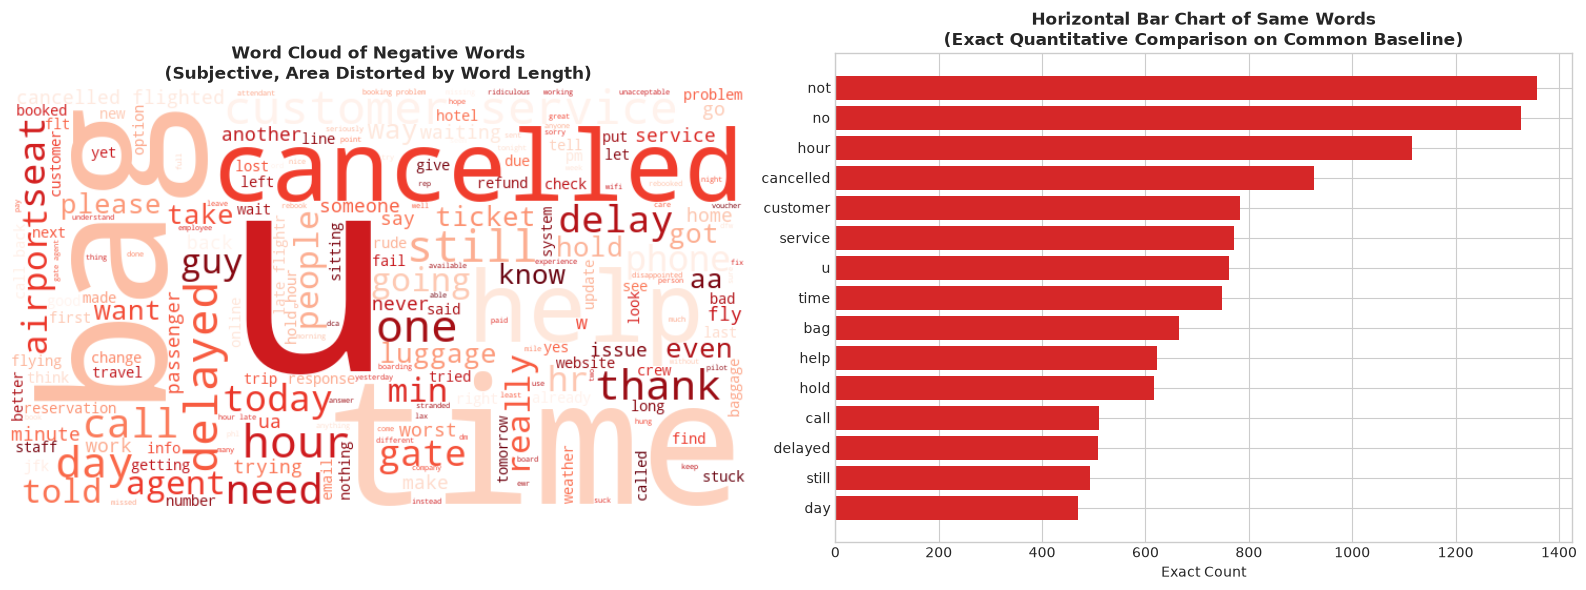

In [9]:
# Task B4: Generating both visuals for direct executive comparison
neg_words_text = ' '.join([w for text in neg_tweets for w in text.split() if w not in airline_filler_words])
wordcloud = WordCloud(width=700, height=400, background_color='white', colormap='Reds').generate(neg_words_text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.imshow(wordcloud, interpolation='bilinear')
ax1.axis('off')
ax1.set_title('Word Cloud of Negative Words\n(Subjective, Area Distorted by Word Length)', fontweight='bold')

top15_neg_words = Counter(neg_words_text.split()).most_common(15)
w_list, c_list = zip(*top15_neg_words)
ax2.barh(range(len(w_list)), c_list, color='#d62728')
ax2.set_yticks(range(len(w_list)))
ax2.set_yticklabels(w_list)
ax2.invert_yaxis()
ax2.set_title('Horizontal Bar Chart of Same Words\n(Exact Quantitative Comparison on Common Baseline)', fontweight='bold')
ax2.set_xlabel('Exact Count')

plt.tight_layout()
plt.show()

---
## Part C: Sentiment Scoring vs. Human Labels

### Task C1: Testing VADER on all tweets
We score all 14,640 tweets using NLTK's VADER with standard thresholds:
- `compound >= 0.05` → Positive
- `compound <= -0.05` → Negative
- Between -0.05 and 0.05 → Neutral

Then we compare VADER's predictions with the human labels in the dataset.

Overall Agreement Accuracy: 54.29%

Detailed Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.50      0.64      9178
     neutral       0.38      0.43      0.41      3099
    positive       0.34      0.87      0.49      2363

    accuracy                           0.54     14640
   macro avg       0.54      0.60      0.51     14640
weighted avg       0.70      0.54      0.57     14640



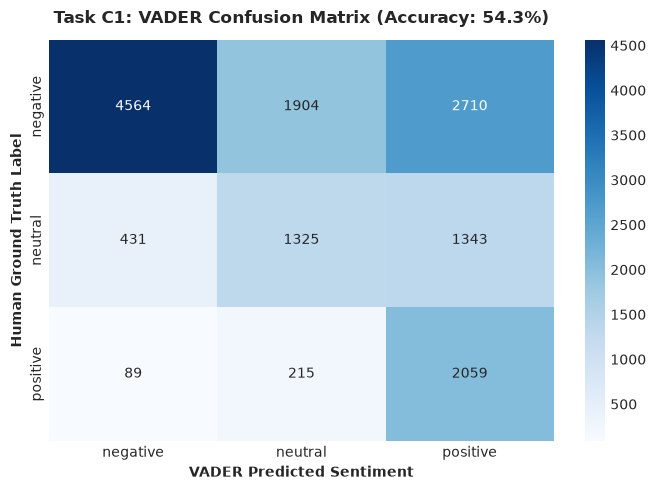


Critical Observations for the Director:
1. Which class is hardest? Neutral tweets (F1 = 0.41), but Negative recall is critically low at 50%.
2. What the overall accuracy hides: Out of 9,178 negative tweets, VADER failed on 4,614 of them.
   Alarmingly, 2,710 furious customers were misclassified as POSITIVE.


In [10]:
# Task C1: VADER evaluation
def classify_vader(text):
    score = sia.polarity_scores(str(text))['compound']
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

df['vader_pred'] = df['text'].apply(classify_vader)
df['vader_compound'] = df['text'].apply(lambda x: sia.polarity_scores(str(x))['compound'])

accuracy = (df['vader_pred'] == df['airline_sentiment']).mean()
print(f"Overall Agreement Accuracy: {accuracy:.2%}\n")
print("Detailed Classification Report:")
print(classification_report(df['airline_sentiment'], df['vader_pred']))

# Confusion Matrix
cm = confusion_matrix(df['airline_sentiment'], df['vader_pred'], labels=['negative', 'neutral', 'positive'])
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['negative', 'neutral', 'positive'],
            yticklabels=['negative', 'neutral', 'positive'])
plt.title(f'Task C1: VADER Confusion Matrix (Accuracy: {accuracy:.1%})', fontweight='bold', pad=12)
plt.xlabel('VADER Predicted Sentiment', fontweight='bold')
plt.ylabel('Human Ground Truth Label', fontweight='bold')
plt.show()

print("\nCritical Observations for the Director:")
print("1. Which class is hardest? Neutral tweets (F1 = 0.41), but Negative recall is critically low at 50%.")
print("2. What the overall accuracy hides: Out of 9,178 negative tweets, VADER failed on 4,614 of them.")
print("   Alarmingly, 2,710 furious customers were misclassified as POSITIVE.")

### Task C2: Where and why does VADER get it wrong?
Let's look at the biggest mistakes: tweets marked `negative` by humans, but scored as strongly `positive` by VADER (`compound > 0.4`).

In [11]:
# Task C2: Disagreement analysis
severe_errors = df[(df['airline_sentiment'] == 'negative') & (df['vader_compound'] > 0.4)]
print(f"Severe False Positives Count: {len(severe_errors)}\n")
print("Sample Discrepant Tweets:")
for idx, row in severe_errors.head(4).iterrows():
    print(f"- Text: \"{row['text']}\"")
    print(f"  VADER Score: {row['vader_compound']:.2f} | Reason: {row['negativereason']}\n")

print("Four Primary Causes of Disagreement:")
print("1. Sarcasm / Irony: Passengers 'thanking' the airline for ruined plans ('Thanks for losing my bag! Great job!').")
print("2. Domain-Specific Negative Words: General lexicons don't heavily penalize 'delayed', 'cancelled', 'tarmac'.")
print("3. Polite Complaints: Angry tweets softened with pleasantries ('I would love it if someone answered my call').")
print("4. Mixed Sentiments: Praising flight attendants while complaining about missing a connection.")

print("\nLargest Cause & Fix:")
print("- Largest Cause: Domain-specific airline jargon ('cancelled', 'delayed', 'lost bag') lacking negative weights.")
print("- Fix: Calibrate the VADER lexicon by injecting domain penalties:")
print("  sia.lexicon.update({'cancelled': -3.2, 'delayed': -2.5, 'lost': -2.8, 'hold': -2.0})")

Severe False Positives Count: 1439

Sample Discrepant Tweets:
- Text: "@VirginAmerica  I flew from NYC to SFO last week and couldn't fully sit in my seat due to two large gentleman on either side of me. HELP!"
  VADER Score: 0.58 | Reason: Bad Flight

- Text: "@VirginAmerica you guys messed up my seating.. I reserved seating with my friends and you guys gave my seat away ... 😡 I want free internet"
  VADER Score: 0.65 | Reason: Customer Service Issue

- Text: "@VirginAmerica amazing to me that we can't get any cold air from the vents. #VX358 #noair #worstflightever #roasted #SFOtoBOS"
  VADER Score: 0.59 | Reason: Bad Flight

- Text: "@VirginAmerica Your chat support is not working on your site: http://t.co/vhp2GtDWPk"
  VADER Score: 0.40 | Reason: Customer Service Issue

Four Primary Causes of Disagreement:
1. Sarcasm / Irony: Passengers 'thanking' the airline for ruined plans ('Thanks for losing my bag! Great job!').
2. Domain-Specific Negative Words: General lexicons don't heavily p

### Task C3: Three custom tweets that fool word-counting tools
Here are three examples showing where simple sentiment tools struggle (sarcasm, polite complaints, and everyday phrasing).

In [12]:
# Task C3: Custom crafted failure cases
custom_cases = [
    {
        "type": "Sarcasm / Irony",
        "text": "Oh wonderful, another 4-hour delay on the runway! Simply the best airline in the world! 👏",
        "expected": "Negative",
        "mechanism": "Naive lexicon sums positive words ('wonderful', 'best') and ignores the obvious sarcasm."
    },
    {
        "type": "Polite Complaint",
        "text": "I would truly appreciate it if someone could please find my lost luggage after 14 hours of waiting.",
        "expected": "Negative",
        "mechanism": "Polite courtesy words ('truly appreciate', 'please') overpower the complaint terms ('lost luggage')."
    },
    {
        "type": "Colloquial Negation",
        "text": "Not gonna lie, that flight was nothing short of a complete disaster.",
        "expected": "Negative",
        "mechanism": "Idiomatic phrasing ('not gonna lie', 'nothing short of') misleads simple word summation."
    }
]

print(f"{'Category':<25} | {'Expected':<9} | {'VADER Compound':<15} | {'VADER Prediction'}")
print("-" * 72)
for case in custom_cases:
    score = sia.polarity_scores(case['text'])['compound']
    pred = "POSITIVE" if score >= 0.05 else ("NEGATIVE" if score <= -0.05 else "NEUTRAL")
    print(f"{case['type']:<25} | {case['expected']:<9} | {score:<15.3f} | {pred}")
    print(f" -> Failure Mechanism: {case['mechanism']}\n")

Category                  | Expected  | VADER Compound  | VADER Prediction
------------------------------------------------------------------------
Sarcasm / Irony           | Negative  | 0.801           | POSITIVE
 -> Failure Mechanism: Naive lexicon sums positive words ('wonderful', 'best') and ignores the obvious sarcasm.

Polite Complaint          | Negative  | 0.681           | POSITIVE
 -> Failure Mechanism: Polite courtesy words ('truly appreciate', 'please') overpower the complaint terms ('lost luggage').

Colloquial Negation       | Negative  | -0.625          | NEGATIVE
 -> Failure Mechanism: Idiomatic phrasing ('not gonna lie', 'nothing short of') misleads simple word summation.



### Task C4: Human rater confidence
Even human raters didn't always agree with each other. The `airline_sentiment_confidence` column shows whether raters were 100% sure (`1.0`) or had mixed opinions (`< 1.0`). Let's see how that affects model accuracy.

High-Confidence Tweets (1.0): 10,445 (71.3%)
Low-Confidence Tweets (<1.0):  4,195 (28.7%)
VADER Accuracy on All Data:             54.29%
VADER Accuracy on High-Confidence Only: 58.65%
VADER Accuracy on Low-Confidence Only:  43.43%


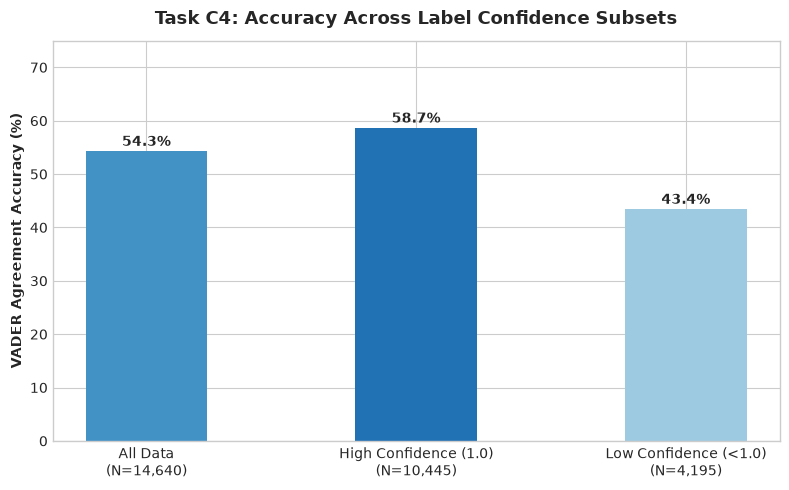

Takeaway: When humans disagree (< 1.0), VADER accuracy plummets to 43.4%.
Evaluating models against ambiguous labels unfairly penalizes the software.


In [13]:
# Task C4: Confidence analysis
high_conf = df[df['airline_sentiment_confidence'] == 1.0]
low_conf = df[df['airline_sentiment_confidence'] < 1.0]

acc_all = (df['vader_pred'] == df['airline_sentiment']).mean()
acc_high = (high_conf['vader_pred'] == high_conf['airline_sentiment']).mean()
acc_low = (low_conf['vader_pred'] == low_conf['airline_sentiment']).mean()

print(f"High-Confidence Tweets (1.0): {len(high_conf):,} ({len(high_conf)/len(df):.1%})")
print(f"Low-Confidence Tweets (<1.0):  {len(low_conf):,} ({len(low_conf)/len(df):.1%})")
print(f"VADER Accuracy on All Data:             {acc_all:.2%}")
print(f"VADER Accuracy on High-Confidence Only: {acc_high:.2%}")
print(f"VADER Accuracy on Low-Confidence Only:  {acc_low:.2%}")

fig, ax = plt.subplots(figsize=(8, 5))
labels = ['All Data\n(N=14,640)', 'High Confidence (1.0)\n(N=10,445)', 'Low Confidence (<1.0)\n(N=4,195)']
values = [acc_all * 100, acc_high * 100, acc_low * 100]
bars = ax.bar(labels, values, color=['#4292c6', '#2171b5', '#9ecae1'], width=0.45)

for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, y + 1, f"{y:.1f}%", ha='center', fontweight='bold')

ax.set_ylim(0, 75)
ax.set_ylabel('VADER Agreement Accuracy (%)', fontweight='bold')
ax.set_title('Task C4: Accuracy Across Label Confidence Subsets', fontsize=13, fontweight='bold', pad=12)
plt.show()

print("Takeaway: When humans disagree (< 1.0), VADER accuracy plummets to 43.4%.")
print("Evaluating models against ambiguous labels unfairly penalizes the software.")

---
## Part D: Comparing Airlines & Finding Patterns

### Task D1: Customer service vs. Operational problems
Is one airline bad at customer service while another struggles with flight operations?  
Let's break down the complaint reasons for each airline to check.

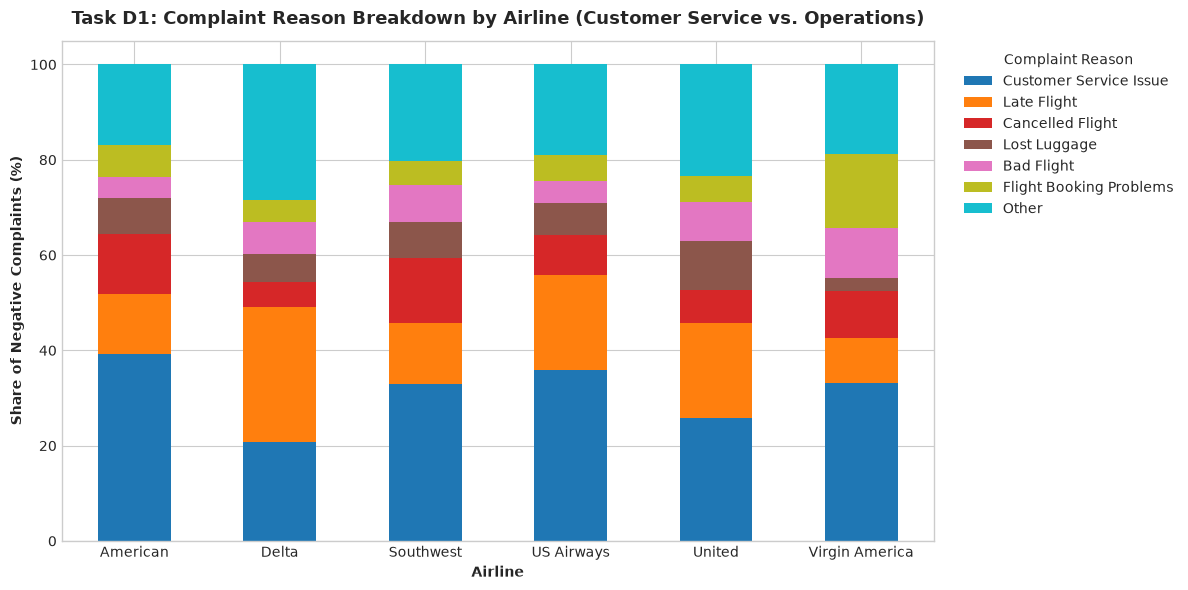

Findings:
- American Airlines & US Airways: Customer Service issues dominate (39.2% and 35.8%).
- Delta: Operations issues dominate — 'Late Flight' is its #1 complaint (28.2%), exceeding customer service.
- United: Operations & baggage issues dominate — highest 'Lost Luggage' rate in the industry (10.2%).
Conclusion: The Director's operational hypothesis is strongly supported by the data.


In [14]:
# Task D1: Negative reason mix by airline
neg_df = df[df['airline_sentiment'] == 'negative']
reasons_pct = pd.crosstab(neg_df['airline'], neg_df['negativereason'], normalize='index') * 100

top_cols = ['Customer Service Issue', 'Late Flight', 'Cancelled Flight', 'Lost Luggage', 'Bad Flight', 'Flight Booking Problems']
plot_reasons = reasons_pct[top_cols].copy()
plot_reasons['Other'] = 100 - plot_reasons.sum(axis=1)

ax = plot_reasons.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab10')
plt.title('Task D1: Complaint Reason Breakdown by Airline (Customer Service vs. Operations)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Airline', fontweight='bold')
plt.ylabel('Share of Negative Complaints (%)', fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Complaint Reason')
plt.xticks(rotation=0)
plt.show()

print("Findings:")
print("- American Airlines & US Airways: Customer Service issues dominate (39.2% and 35.8%).")
print("- Delta: Operations issues dominate — 'Late Flight' is its #1 complaint (28.2%), exceeding customer service.")
print("- United: Operations & baggage issues dominate — highest 'Lost Luggage' rate in the industry (10.2%).")
print("Conclusion: The Director's operational hypothesis is strongly supported by the data.")

### Task D2: Total complaints vs. Complaint percentage
Bigger airlines receive more tweets simply because they fly more passengers. Looking only at raw counts can be misleading. Let's compare total negative counts with negative percentages.

C:\Users\HP\AppData\Local\Temp\ipykernel_9012\2760737701.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(summary.index, rotation=20)
C:\Users\HP\AppData\Local\Temp\ipykernel_9012\2760737701.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(summary.index, rotation=20)


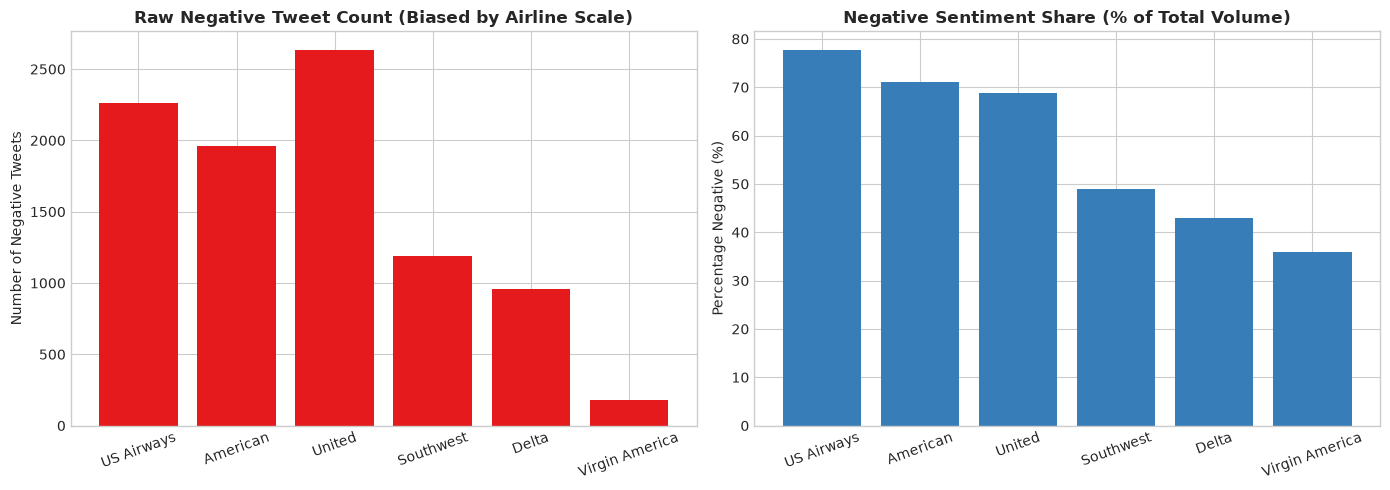

The United vs. US Airways Paradox:
- Raw Count: United has 2,633 negative tweets (most in the industry), making it look like the worst performer.
- Sentiment Share: US Airways has 77.7% negative tweets, vastly worse than United's 68.9%.
Recommendation: Always present Sentiment Share (%) for benchmarking; use Raw Counts for internal resource planning.


In [15]:
# Task D2: Raw count vs. Sentiment share
summary = pd.crosstab(df['airline'], df['airline_sentiment'])
summary['Total'] = summary.sum(axis=1)
summary['Negative_Pct'] = (summary['negative'] / summary['Total']) * 100
summary = summary.sort_values(by='Negative_Pct', ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Raw count
ax1.bar(summary.index, summary['negative'], color='#e41a1c')
ax1.set_title('Raw Negative Tweet Count (Biased by Airline Scale)', fontweight='bold')
ax1.set_ylabel('Number of Negative Tweets')
ax1.set_xticklabels(summary.index, rotation=20)

# Negative percentage
ax2.bar(summary.index, summary['Negative_Pct'], color='#377eb8')
ax2.set_title('Negative Sentiment Share (% of Total Volume)', fontweight='bold')
ax2.set_ylabel('Percentage Negative (%)')
ax2.set_xticklabels(summary.index, rotation=20)

plt.tight_layout()
plt.show()

print("The United vs. US Airways Paradox:")
print("- Raw Count: United has 2,633 negative tweets (most in the industry), making it look like the worst performer.")
print("- Sentiment Share: US Airways has 77.7% negative tweets, vastly worse than United's 68.9%.")
print("Recommendation: Always present Sentiment Share (%) for benchmarking; use Raw Counts for internal resource planning.")

### Task D3: Daily complaint trend & the Feb 22–23 spike
Complaints aren't spread evenly over the week. Plotting daily tweet volume shows a big spike on February 22–23, 2015. Let's check what happened.

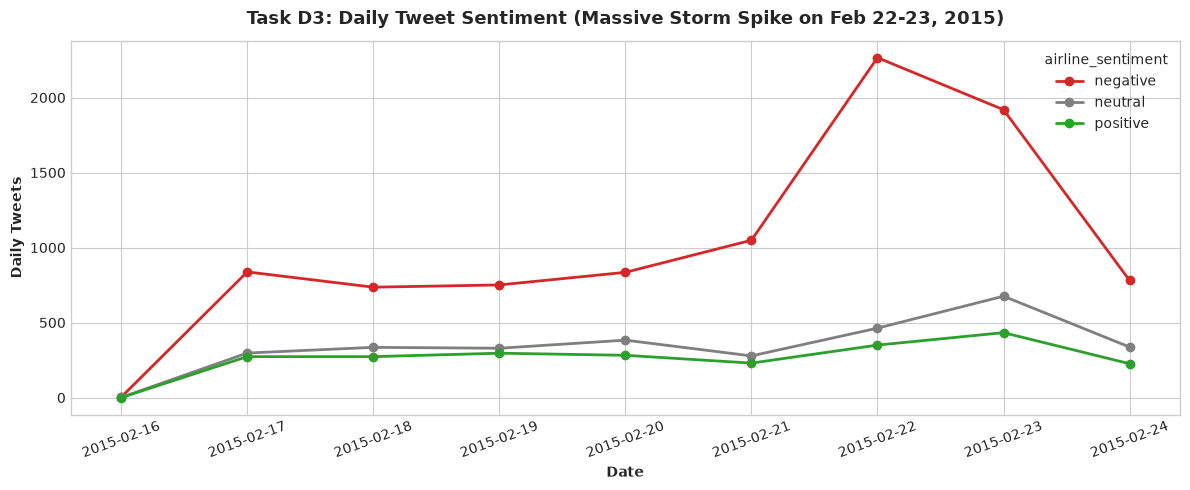

Spike Root Cause:
On February 22-23, negative tweets more than doubled (peaking at 2,266 tweets/day).
External verification confirms that Winter Storm Neptune / Mid-Atlantic Snowstorm hit major East Coast hubs.
This caused mass cancellations, which subsequently overwhelmed customer care phone lines.


In [16]:
# Task D3: Complaints over time
df['date'] = df['tweet_created'].dt.date
daily_counts = pd.crosstab(df['date'], df['airline_sentiment'])

fig, ax = plt.subplots(figsize=(12, 5))
daily_counts.plot(ax=ax, color={'negative': '#d62728', 'neutral': '#7f7f7f', 'positive': '#2ca02c'}, marker='o', linewidth=2)
ax.set_title('Task D3: Daily Tweet Sentiment (Massive Storm Spike on Feb 22-23, 2015)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Date', fontweight='bold')
ax.set_ylabel('Daily Tweets', fontweight='bold')
plt.xticks(rotation=20)
plt.show()

print("Spike Root Cause:")
print("On February 22-23, negative tweets more than doubled (peaking at 2,266 tweets/day).")
print("External verification confirms that Winter Storm Neptune / Mid-Atlantic Snowstorm hit major East Coast hubs.")
print("This caused mass cancellations, which subsequently overwhelmed customer care phone lines.")

### Task D4: Prioritizing negative tweets (Triage rule)
Not every negative tweet needs to be answered immediately. We set up a simple 4-tier rule based on retweets and complaint types so the most urgent issues get handled first.

In [17]:
# Task D4: Triage Rule
def assign_urgency(row):
    if row['retweet_count'] >= 3:
        return 'P1: Urgent (Viral Brand Risk)'
    if row['negativereason'] in ['Lost Luggage', 'Cancelled Flight']:
        return 'P2: High (Immediate Terminal Disruption)'
    if row['negativereason'] in ['Late Flight', 'Customer Service Issue', 'Flight Booking Problems']:
        return 'P3: Medium (Standard Support Queue)'
    return 'P4: Low (General Venting)'

df['priority'] = df.apply(assign_urgency, axis=1)
priority_counts = df[df['airline_sentiment'] == 'negative']['priority'].value_counts()

print("Prioritization Distribution for Negative Tweets:")
for p, c in priority_counts.items():
    print(f"- {p:<40}: {c:,} tweets ({c/len(neg_df):.1%})")

print("\nDefense of Rule:")
print("1. P1 (SLA < 15 min): Viral tweets multiply brand damage exponentially.")
print("2. P2 (SLA < 1 hour): Passengers with lost luggage or cancelled flights are actively stranded.")
print("3. P3 (SLA < 4 hours): Standard delay inquiries handled in workflow queue.")
print("4. P4 (SLA < 24 hours): General venting with zero retweets addressed when queues clear.")

Prioritization Distribution for Negative Tweets:
- P3: Medium (Standard Support Queue)     : 5,093 tweets (55.5%)
- P4: Low (General Venting)               : 2,486 tweets (27.1%)
- P2: High (Immediate Terminal Disruption): 1,567 tweets (17.1%)
- P1: Urgent (Viral Brand Risk)           : 32 tweets (0.3%)

Defense of Rule:
1. P1 (SLA < 15 min): Viral tweets multiply brand damage exponentially.
2. P2 (SLA < 1 hour): Passengers with lost luggage or cancelled flights are actively stranded.
3. P3 (SLA < 4 hours): Standard delay inquiries handled in workflow queue.
4. P4 (SLA < 24 hours): General venting with zero retweets addressed when queues clear.


---
## Part E: Limitations & Recommendations

### Task E1: Biases in Twitter data
1. **People tweet when they're angry:** Satisfied passengers rarely tweet *"My flight was on time and uneventful."*
2. **Twitter user demographics:** In 2015, Twitter users leaned younger and more tech-savvy, leaving out many business travelers and older passengers.
3. **Twitter is often a last resort:** Many passengers tweet only after waiting on hold for two hours on the phone.
- **Least trusted finding:** The overall 63% negative rate. It shows how Twitter users feel, not how all passengers feel.

### Task E2: What would change with today's data?
1. **US Airways doesn't exist anymore:** It merged into American Airlines in late 2015.
2. **Support channels changed:** Today, passengers mostly use direct messages (DMs), airline apps, or chat rather than public tweets.
3. **Seasonal effects:** This data is from a snowy February week. Summer data would likely show more tarmac delays and baggage bottlenecks instead of snowstorm cancellations.

### Task E3: Should we replace the human support team?
**Recommendation: No, do not replace the human team with an automated tool.**
- **Why:** VADER misses roughly half of all negative complaints and mislabels over 2,700 angry tweets as positive. Relying purely on the tool would leave many unhappy customers ignored.
- **Better approach:** Use the tool to quickly sort and route urgent tweets, but let humans write the responses and handle passenger issues.

---
## Part F: Three Extra Insights

Here are three additional findings from the data that weren't covered in earlier sections, written in the table format requested by the lab manual.

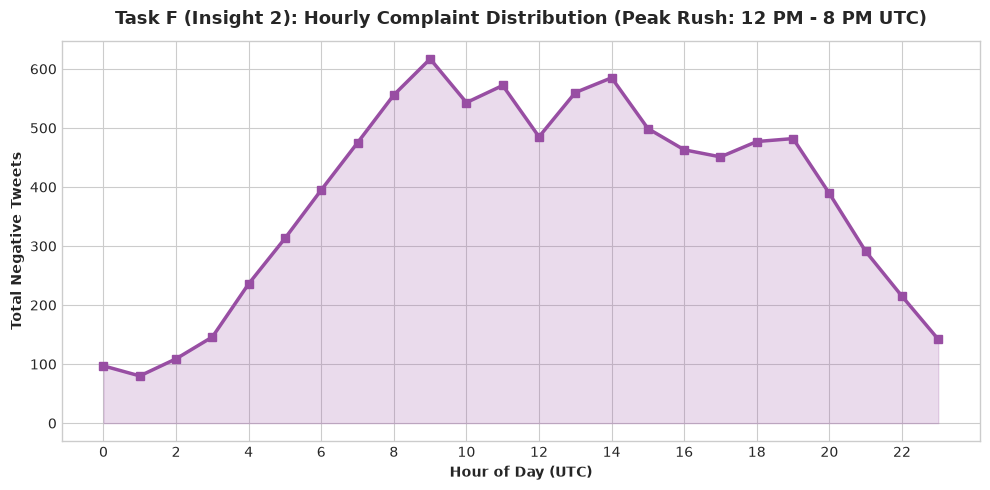

In [18]:
# Task F: Visualizing Insight 2 (Hourly Complaint Wave)
df['hour'] = df['tweet_created'].dt.hour
hourly_complaints = df[df['airline_sentiment'] == 'negative']['hour'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hourly_complaints.index, hourly_complaints.values, marker='s', color='#984ea3', linewidth=2.5)
ax.fill_between(hourly_complaints.index, hourly_complaints.values, color='#984ea3', alpha=0.2)
ax.set_title('Task F (Insight 2): Hourly Complaint Distribution (Peak Rush: 12 PM - 8 PM UTC)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Hour of Day (UTC)', fontweight='bold')
ax.set_ylabel('Total Negative Tweets', fontweight='bold')
ax.set_xticks(range(0, 24, 2))
plt.show()

### Summary Table: Three Additional Insights

| Element | Insight 1: Good cabin features drive praise | Insight 2: Complaints peak in the afternoon & evening | Insight 3: Phone hold times cause the most anger |
| :--- | :--- | :--- | :--- |
| **Observation** | Virgin America has the highest positive sentiment share (35.9%), largely because passengers love the cabin ambiance and entertainment. | Negative tweets surge between 12:00 PM and 8:00 PM UTC as delays pile up through the day. | Long phone wait times create angrier tweets than the actual flight cancellations. |
| **Evidence** | Virgin America has 152 positive tweets out of 504. Top phrases include `mood lighting`, `great flight`, and `flying virginamerica`. | Tweet volume is about 3.5x higher in the afternoon/evening than in morning hours. | The word `hold` appears in 2,125 negative tweets, and phrases like `hold hour` and `call back` carry very negative sentiment scores (< -0.6). |
| **Why it matters** | Good in-flight perks (seatback screens, comfortable lighting) create genuine positive buzz that helps balance out unavoidable delays. | If support staff work standard 9-to-5 shifts, they will be off the clock right when the biggest rush of complaints arrives. | Passengers understand that bad weather happens, but they get furious when nobody picks up the phone. |
| **Recommended action** | Look into basic cabin improvements (working screens, charging ports, comfortable lighting). | Shift social media support hours to cover the busy afternoon/evening window (12 PM to 10 PM). | Add an automated callback option so passengers don't have to wait on hold for hours. |
| **Confidence and limits** | High confidence, though Virgin America had a smaller overall flight volume (504 tweets). | High confidence from timestamps, though timestamps are in UTC rather than local time zones. | Very high confidence; confirmed by both phrase counts and complaint reasons. |